## **1. IMPORT LIBRARIES**

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Imported!")

Imported!


## **2. PROJECT PATHS**

In [6]:
PROJECT_ROOT = os.path.abspath("..")

PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

# Dataset
DATA_PATH = os.path.join(
    PROCESSED_DIR,
    "historical_clean_bhopal.csv"
)

# Saved LSTM model
MODEL_PATH = os.path.join(
    MODELS_DIR,
    "weather_lstm_bhopal_multistep.keras"
)

# Saved scaler
SCALER_PATH = os.path.join(
    MODELS_DIR,
    "scaler_bhopal.pkl"
)


# **3. CHECK FILES**

In [7]:
print("Project Root:", PROJECT_ROOT)

print("\nChecking required files:")

print("Dataset:", os.path.exists(DATA_PATH))
print("LSTM Model:", os.path.exists(MODEL_PATH))
print("Scaler:", os.path.exists(SCALER_PATH))

Project Root: c:\Users\HP\Desktop\PROJECTS\weather-elt-project

Checking required files:
Dataset: True
LSTM Model: True
Scaler: True


## **4. LOAD HISTORICAL DATASET**

In [9]:
df = pd.read_csv(DATA_PATH)

# Convert time column to datetime
df["time"] = pd.to_datetime(df["time"])

# Sort data chronologically
df = df.sort_values("time").reset_index(drop=True)


## **5. DATASET OVERVIEW**

In [10]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

Dataset Shape: (17520, 7)

Column Names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'hour', 'month']

Data Types:
time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
wind_speed_10m                 float64
hour                             int64
month                            int64
dtype: object

First 5 Records:


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,hour,month
0,2022-01-01 00:00:00,12.4,88,0.0,7.6,0,1
1,2022-01-01 01:00:00,12.1,90,0.0,6.9,1,1
2,2022-01-01 02:00:00,11.6,92,0.0,6.2,2,1
3,2022-01-01 03:00:00,11.4,92,0.0,6.6,3,1
4,2022-01-01 04:00:00,11.5,90,0.0,6.0,4,1



Last 5 Records:


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,hour,month
17515,2023-12-31 19:00:00,20.1,74,0.0,9.2,19,12
17516,2023-12-31 20:00:00,19.9,74,0.0,6.9,20,12
17517,2023-12-31 21:00:00,19.2,79,0.0,7.2,21,12
17518,2023-12-31 22:00:00,17.9,86,0.0,8.9,22,12
17519,2023-12-31 23:00:00,17.0,90,0.0,5.4,23,12


## **6. DATA QUALITY CHECKS**

In [11]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Timestamps:")
print(df["time"].duplicated().sum())

print("\nChronological Order:")
print(df["time"].is_monotonic_increasing)

# Check missing hourly timestamps
time_difference = df["time"].diff().dropna()

print("\nTime Interval Distribution:")
print(time_difference.value_counts().head())

print("\nMissing Hourly Intervals:")
print((time_difference != pd.Timedelta(hours=1)).sum())



Missing Values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
hour                    0
month                   0
dtype: int64

Duplicate Timestamps:
0

Chronological Order:
True

Time Interval Distribution:
time
0 days 01:00:00    17519
Name: count, dtype: int64

Missing Hourly Intervals:
0


## **7. LOAD TRAINED LSTM MODEL**

In [12]:
model = load_model(MODEL_PATH)

print("LSTM Model Loaded Successfully!")

LSTM Model Loaded Successfully!


## **8. LOAD ORIGINAL SCALER**

In [13]:
scaler = joblib.load(SCALER_PATH)

print("Scaler Loaded Successfully!")

Scaler Loaded Successfully!


## **9. MODEL INFORMATION**

In [14]:
print("\nModel Summary:")
model.summary()


Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 48, 64)         │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │         7,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,514 (474.67 KB)

 Trainable params: 40,504 (158.22 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 81,010 (316.45 KB)

## **10. SCALER INFORMATION**

In [15]:
print("\nScaler Feature Range:")
print("Minimum:", scaler.data_min_)
print("Maximum:", scaler.data_max_)

print("\nNumber of Features:", scaler.n_features_in_)


Scaler Feature Range:
Minimum: [6.5 6.  0.  0.4 0.  1. ]
Maximum: [ 44.  100.   23.9  41.5  23.   12. ]

Number of Features: 6


## **11. DEFINE FEATURES AND FORECAST SETTINGS**

In [16]:
FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "hour",
    "month"
]

TARGET_COL = "temperature_2m"

SEQUENCE_LENGTH = 48
FORECAST_HORIZON = 120

## **12. IDENTIFY TEST DATASET**

In [17]:
total_records = len(df)

train_end_idx = int(total_records * 0.70)
val_end_idx = int(total_records * 0.85)
test_start_idx = val_end_idx

print("Total Records:", total_records)
print("Training End Index:", train_end_idx)
print("Validation End Index:", val_end_idx)
print("Test Start Index:", test_start_idx)

print("\nTest Period:")
print("Start:", df["time"].iloc[test_start_idx])
print("End:", df["time"].iloc[-1])

Total Records: 17520
Training End Index: 12264
Validation End Index: 14892
Test Start Index: 14892

Test Period:
Start: 2023-09-13 12:00:00
End: 2023-12-31 23:00:00


## **13. SCALE DATA USING ORIGINAL SCALER**

In [18]:
scaled_data = scaler.transform(df[FEATURES])

target_idx = FEATURES.index(TARGET_COL)

print("\nScaled Data Shape:", scaled_data.shape)


Scaled Data Shape: (17520, 6)


## **14. CREATE NON-OVERLAPPING FORECAST WINDOWS**

In [19]:
forecast_starts = np.arange(
    test_start_idx,
    total_records - FORECAST_HORIZON + 1,
    FORECAST_HORIZON
)

X_eval = np.array([
    scaled_data[start - SEQUENCE_LENGTH : start]
    for start in forecast_starts
])

y_actual = np.array([
    df[TARGET_COL].iloc[start : start + FORECAST_HORIZON].values
    for start in forecast_starts
])

forecast_start_times = df["time"].iloc[forecast_starts].reset_index(drop=True)

## **15. DISPLAY FORECAST WINDOW INFORMATION**

In [20]:
print("\nEvaluation Dataset Prepared!")

print("Number of Forecast Windows:", len(forecast_starts))
print("Input Shape:", X_eval.shape)
print("Actual Target Shape:", y_actual.shape)

print("\nForecast Starting Times:")
display(forecast_start_times)

print("\nFirst Forecast Window:")
print("Input Period:",
      df["time"].iloc[forecast_starts[0] - SEQUENCE_LENGTH],
      "to",
      df["time"].iloc[forecast_starts[0] - 1])

print("Prediction Period:",
      df["time"].iloc[forecast_starts[0]],
      "to",
      df["time"].iloc[forecast_starts[0] + FORECAST_HORIZON - 1])


Evaluation Dataset Prepared!
Number of Forecast Windows: 21
Input Shape: (21, 48, 6)
Actual Target Shape: (21, 120)

Forecast Starting Times:


0    2023-09-13 12:00:00
1    2023-09-18 12:00:00
2    2023-09-23 12:00:00
3    2023-09-28 12:00:00
4    2023-10-03 12:00:00
5    2023-10-08 12:00:00
6    2023-10-13 12:00:00
7    2023-10-18 12:00:00
8    2023-10-23 12:00:00
9    2023-10-28 12:00:00
10   2023-11-02 12:00:00
11   2023-11-07 12:00:00
12   2023-11-12 12:00:00
13   2023-11-17 12:00:00
14   2023-11-22 12:00:00
15   2023-11-27 12:00:00
16   2023-12-02 12:00:00
17   2023-12-07 12:00:00
18   2023-12-12 12:00:00
19   2023-12-17 12:00:00
20   2023-12-22 12:00:00
Name: time, dtype: datetime64[us]


First Forecast Window:
Input Period: 2023-09-11 12:00:00 to 2023-09-13 11:00:00
Prediction Period: 2023-09-13 12:00:00 to 2023-09-18 11:00:00


## **16. GENERATE LSTM PREDICTIONS**

In [21]:
predictions_scaled = model.predict(
    X_eval,
    verbose=0
)

print("Scaled Predictions Shape:", predictions_scaled.shape)

Scaled Predictions Shape: (21, 120)


## **17. CONVERT PREDICTIONS BACK TO CELSIUS**

In [22]:
# Create a temporary array for inverse scaling
dummy_array = np.zeros(
    (predictions_scaled.size, len(FEATURES))
)

# Insert predicted temperature values
dummy_array[:, target_idx] = predictions_scaled.flatten()

# Reverse scaling
predictions_original = scaler.inverse_transform(dummy_array)

# Extract temperature predictions
y_pred = predictions_original[:, target_idx].reshape(
    len(forecast_starts),
    FORECAST_HORIZON
)

## **18. VALIDATE FORECAST OUTPUTS**

In [23]:
print("\nForecast Evaluation Results")

print("Actual Temperature Shape:", y_actual.shape)
print("Predicted Temperature Shape:", y_pred.shape)

print("\nFirst Forecast - Actual Temperatures:")
print(y_actual[0][:10])

print("\nFirst Forecast - Predicted Temperatures:")
print(y_pred[0][:10])


Forecast Evaluation Results
Actual Temperature Shape: (21, 120)
Predicted Temperature Shape: (21, 120)

First Forecast - Actual Temperatures:
[27.8 28.7 29.  28.5 27.3 26.  25.4 25.1 24.8 24.6]

First Forecast - Predicted Temperatures:
[28.54638347 28.59990472 28.39752087 28.16866362 27.51388276 26.83054307
 26.19012767 25.72792941 25.26776516 25.06704541]


## **19. CHECK FORECAST INTERVALS**

In [24]:
forecast_intervals = np.diff(forecast_starts)

print("\nForecast Interval Check:")

print("All intervals are 120 hours:",
      np.all(forecast_intervals == FORECAST_HORIZON))

print("No overlapping target windows:",
      len(np.unique(forecast_starts)) == len(forecast_starts))


Forecast Interval Check:
All intervals are 120 hours: True
No overlapping target windows: True


## **20. CREATE FORECAST RESULTS DATAFRAME**

In [25]:
forecast_results = pd.DataFrame({
    "forecast_origin": np.repeat(
        forecast_start_times.to_numpy(),
        FORECAST_HORIZON
    ),

    "time": np.concatenate([
        df["time"].iloc[start:start + FORECAST_HORIZON].to_numpy()
        for start in forecast_starts
    ]),

    "forecast_hour": np.tile(
        np.arange(1, FORECAST_HORIZON + 1),
        len(forecast_starts)
    ),

    "forecast_day": np.tile(
        np.repeat(np.arange(1, 6), 24),
        len(forecast_starts)
    ),

    "actual_temperature": y_actual.flatten(),

    "predicted_temperature": y_pred.flatten()
})


print("\nFinal Forecast Results:")
print("Total Evaluated Records:", len(forecast_results))

display(forecast_results.head(10))


Final Forecast Results:
Total Evaluated Records: 2520


,forecast_origin,time,forecast_hour,forecast_day,actual_temperature,predicted_temperature
0,2023-09-13 12:00:00,2023-09-13 12:00:00,1,1,27.8,28.546383
1,2023-09-13 12:00:00,2023-09-13 13:00:00,2,1,28.7,28.599905
2,2023-09-13 12:00:00,2023-09-13 14:00:00,3,1,29.0,28.397521
3,2023-09-13 12:00:00,2023-09-13 15:00:00,4,1,28.5,28.168664
4,2023-09-13 12:00:00,2023-09-13 16:00:00,5,1,27.3,27.513883
5,2023-09-13 12:00:00,2023-09-13 17:00:00,6,1,26.0,26.830543
6,2023-09-13 12:00:00,2023-09-13 18:00:00,7,1,25.4,26.190128
7,2023-09-13 12:00:00,2023-09-13 19:00:00,8,1,25.1,25.727929
8,2023-09-13 12:00:00,2023-09-13 20:00:00,9,1,24.8,25.267765
9,2023-09-13 12:00:00,2023-09-13 21:00:00,10,1,24.6,25.067045


# **21. OVERALL MODEL EVALUATION**

In [26]:
overall_mae = mean_absolute_error(
    y_actual.flatten(),
    y_pred.flatten()
)

overall_rmse = np.sqrt(
    mean_squared_error(
        y_actual.flatten(),
        y_pred.flatten()
    )
)

overall_r2 = r2_score(
    y_actual.flatten(),
    y_pred.flatten()
)


print("NON-OVERLAPPING FORECAST EVALUATION")
print("-----------------------------------")

print(f"Overall MAE  : {overall_mae:.4f} °C")
print(f"Overall RMSE : {overall_rmse:.4f} °C")
print(f"Overall R²   : {overall_r2:.4f}")

NON-OVERLAPPING FORECAST EVALUATION
-----------------------------------
Overall MAE  : 1.2172 °C
Overall RMSE : 1.5372 °C
Overall R²   : 0.9097


## **20. DAY-WISE MODEL EVALUATION**

In [27]:
daywise_results = []

for day in range(5):

    # Select 24 hours for the current forecast day
    actual_day = y_actual[:, day * 24 : (day + 1) * 24]
    predicted_day = y_pred[:, day * 24 : (day + 1) * 24]

    mae = mean_absolute_error(
        actual_day.flatten(),
        predicted_day.flatten()
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_day.flatten(),
            predicted_day.flatten()
        )
    )

    r2 = r2_score(
        actual_day.flatten(),
        predicted_day.flatten()
    )

    daywise_results.append({
        "Forecast Day": f"Day {day + 1}",
        "MAE (°C)": mae,
        "RMSE (°C)": rmse,
        "R2": r2
    })


# Convert results into DataFrame
daywise_results = pd.DataFrame(daywise_results)


print("\nDAY-WISE EVALUATION")
display(daywise_results.round(4))


DAY-WISE EVALUATION


,Forecast Day,MAE (°C),RMSE (°C),R2
0,Day 1,0.9545,1.2559,0.9412
1,Day 2,1.1371,1.4123,0.9255
2,Day 3,1.3477,1.6987,0.8957
3,Day 4,1.3535,1.6622,0.8914
4,Day 5,1.2934,1.6106,0.8923


## **21. VISUALIZE DAY-WISE PERFORMANCE**

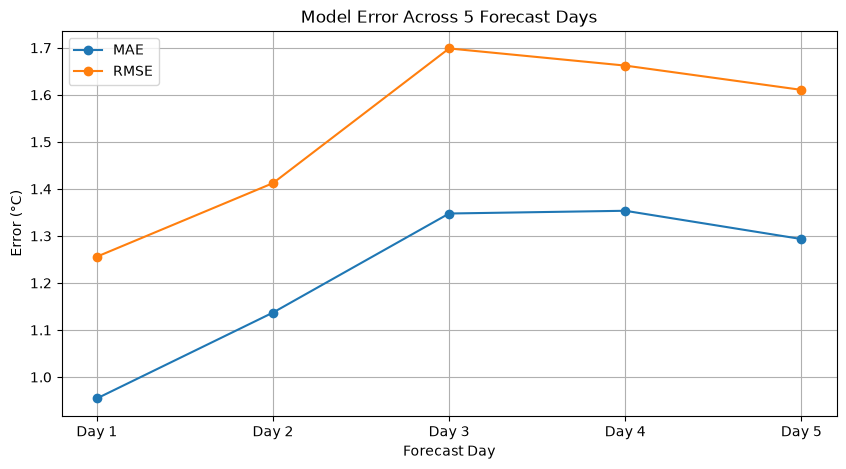

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    daywise_results["Forecast Day"],
    daywise_results["MAE (°C)"],
    marker="o",
    label="MAE"
)

plt.plot(
    daywise_results["Forecast Day"],
    daywise_results["RMSE (°C)"],
    marker="o",
    label="RMSE"
)

plt.title("Model Error Across 5 Forecast Days")
plt.xlabel("Forecast Day")
plt.ylabel("Error (°C)")
plt.legend()
plt.grid(True)
plt.show()

## **22. ACTUAL VS PREDICTED TEMPERATURE**
### **FIRST FORECAST WINDOW (120 HOURS)**

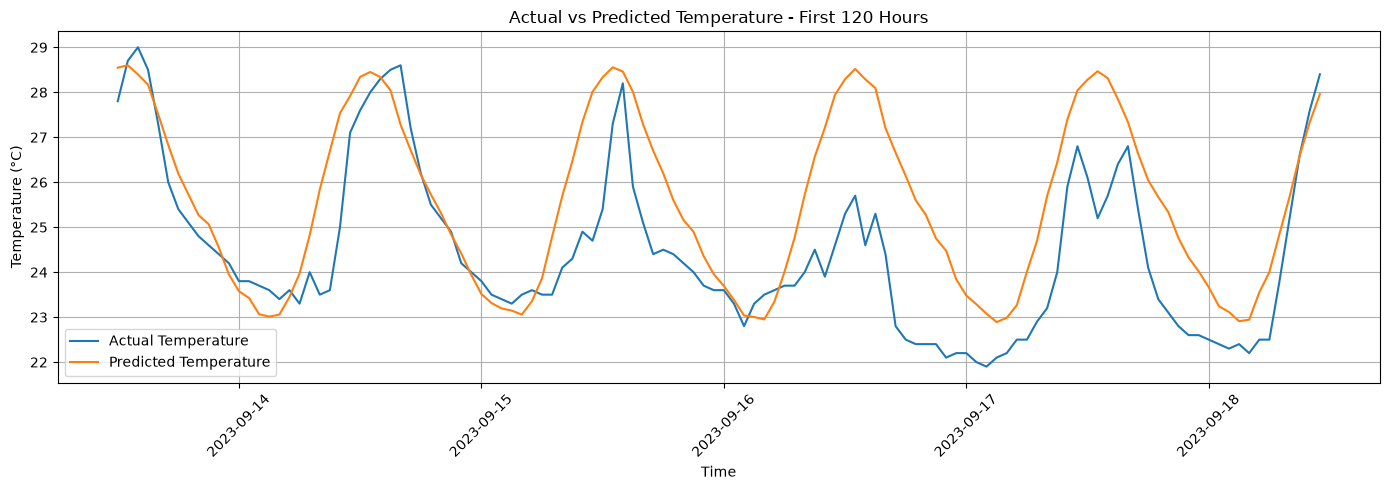

In [30]:
first_forecast = forecast_results[
    forecast_results["forecast_origin"] == forecast_results["forecast_origin"].iloc[0]
]

plt.figure(figsize=(14, 5))

plt.plot(
    first_forecast["time"],
    first_forecast["actual_temperature"],
    label="Actual Temperature"
)

plt.plot(
    first_forecast["time"],
    first_forecast["predicted_temperature"],
    label="Predicted Temperature"
)

plt.title("Actual vs Predicted Temperature - First 120 Hours")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **SAVE NON-OVERLAPPING EVALUATION RESULTS**

In [31]:
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results", "evaluation")

os.makedirs(RESULTS_DIR, exist_ok=True)

# Save all forecast predictions
forecast_results.to_csv(
    os.path.join(RESULTS_DIR, "non_overlapping_forecast_results.csv"),
    index=False
)

# Save day-wise evaluation metrics
daywise_results.to_csv(
    os.path.join(RESULTS_DIR, "non_overlapping_daywise_metrics.csv"),
    index=False
)

# Save overall evaluation metrics
overall_results = pd.DataFrame([{
    "MAE": overall_mae,
    "RMSE": overall_rmse,
    "R2": overall_r2,
    "Forecast_Windows": len(forecast_starts),
    "Forecast_Horizon_Hours": FORECAST_HORIZON,
    "Total_Evaluated_Hours": len(forecast_results)
}])

overall_results.to_csv(
    os.path.join(RESULTS_DIR, "non_overlapping_overall_metrics.csv"),
    index=False
)

print("Evaluation results saved successfully!")
print("Location:", RESULTS_DIR)

Evaluation results saved successfully!
Location: c:\Users\HP\Desktop\PROJECTS\weather-elt-project\results\evaluation
